# Factor Spanning Tests

A factor can earn a positive average return without adding anything to an investor's existing opportunity set. Its return may simply compensate for exposure to strategies the investor already holds. The relevant question is therefore whether the candidate delivers average return beyond what those exposures explain.

Factor-spanning tests address this question with time-series regressions. We first explain the benchmark, the interpretation of alpha, and the distinction between return exposure and investment value. We then use the published Fama–French factor returns to ask whether size, value, profitability, and investment strategies add to a market-only benchmark. Notebook 07 applies factor models to test portfolios and evaluates joint pricing restrictions.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT / "src"))
from factor_asset_pricing.french_data import load_french, sample_coverage
RAW = ROOT / "data/raw/french"
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from factor_asset_pricing.asset_pricing_tests import factor_regressions
pd.options.display.float_format="{:,.3f}".format; plt.style.use("seaborn-v0_8-whitegrid")
factors = load_french("ff5", RAW).loc["1963-07":"2024-12"]
assert len(factors) == 738 and not factors.isna().any().any()
factor_panel=factors[["MKT","SMB","HML","RMW","CMA"]]
display(sample_coverage(factor_panel))


,start,end,observations,missing
MKT,1963-07-01 00:00:00,2024-12-01 00:00:00,738,0
SMB,1963-07-01 00:00:00,2024-12-01 00:00:00,738,0
HML,1963-07-01 00:00:00,2024-12-01 00:00:00,738,0
RMW,1963-07-01 00:00:00,2024-12-01 00:00:00,738,0
CMA,1963-07-01 00:00:00,2024-12-01 00:00:00,738,0


## 1. Factor spanning: does a factor add investment value?

### 1.1 Asset-pricing benchmarks

CAPM and multifactor models provide benchmarks against which to evaluate a candidate investment. Under CAPM, an asset's expected excess return depends only on its exposure to the market excess return:

$$E[R_i-R_f]=\beta_{i,M}E[R_M-R_f],\qquad \beta_{i,M}=\frac{\operatorname{Cov}(R_i-R_f,R_M-R_f)}{\operatorname{Var}(R_M-R_f)}.$$

The corresponding time-series regression is

$$R^e_{i,t}=\alpha_i+\beta_{i,M}MKT_t+\varepsilon_{i,t},\qquad MKT_t=R_{M,t}-R_{f,t}.$$

The intercept is Jensen's alpha (Jensen, 1968): average excess return left unexplained by market exposure. The CAPM restriction is tested as

$$H_0:\alpha_i=0,\qquad H_1:\alpha_i\neq0.$$

A rejection provides evidence against the model's expected-return restriction. It does not, by itself, distinguish omitted risk from mispricing or market-proxy error. The theoretical market portfolio includes all risky wealth, so using an equity-market proxy also makes this a test of that proxy.

A multifactor benchmark allows exposure to several factor returns:

$$R^e_{i,t}=\alpha_i+\boldsymbol\beta_i'\mathbf F_t+\varepsilon_{i,t}.$$

The choice of benchmark determines the meaning of abnormal return. Alpha relative to MKT can disappear when additional factors are included. Conversely, a significant loading establishes exposure to a factor, but does not identify a distinct priced risk.

### 1.2 Alpha, exposure, and spanning

A factor-spanning regression treats a candidate factor's excess-return payoff, $G_t$, as the dependent variable and established factors as the benchmark:

$$G_t=\alpha+\boldsymbol\beta'\mathbf F_t+\varepsilon_t.$$

As explained in Notebook 03, a long-only candidate enters as its return minus the risk-free return. A self-financing long–short factor is already an excess-return payoff. The risk-free return must not be subtracted again. The benchmark factors are likewise expressed as excess or self-financing returns.

For the population linear projection, $E[\varepsilon_t]=0$ and $E[\varepsilon_t\mathbf F_t]=\mathbf0$. Taking expectations gives

$$\alpha=E[G_t]-\boldsymbol\beta'E[\mathbf F_t].$$

Alpha therefore measures average return unexplained by benchmark exposure. The loadings measure that exposure, while adjusted $R^2$ summarizes explained time-series variation after accounting for model size. A regression can explain much of a factor's monthly variation while failing to explain its average return. Low fit, by itself, does not establish that a factor improves the investment opportunity set.

The central spanning hypothesis is

$$H_0:\alpha=0,\qquad H_1:\alpha\neq0.$$

These are unconditional regressions with constant population projection coefficients. They do not estimate state-dependent expected returns or exposures.

### 1.3 The investment interpretation

The regression separates the candidate into benchmark exposure and a residual payoff, $G_t-\boldsymbol\beta'\mathbf F_t$. This payoff has mean $\alpha$ and is uncorrelated with the benchmark factors. A population nonzero alpha therefore offers an additional source of expected excess return that can be combined with the benchmark investments.

With nonsingular covariance matrices, unrestricted long/short trading, and a risk-free asset, a nonzero population alpha increases the maximum attainable squared Sharpe ratio. Zero alpha means the candidate does not increase that maximum (Gibbons, Ross, and Shanken, 1989). This is the excess-return mean–variance spanning restriction used here. Notebook 06 develops the portfolio geometry and maximum-Sharpe interpretation.

Exact return replication is stronger: it also requires $\operatorname{Var}(\varepsilon_t)=0$. A zero-alpha candidate can still have substantial unexplained monthly variation, even though it does not improve the population maximum Sharpe ratio under these assumptions.

A statistically significant estimated alpha provides evidence against the population zero-alpha restriction. A merely nonzero sample estimate is insufficient, and failure to reject does not prove spanning. Estimated opportunity-set improvements do not guarantee future abnormal returns. Trading costs, position constraints, estimation uncertainty, and out-of-sample performance determine whether the apparent improvement is useful in practice.

### 1.4 Estimation and inference

OLS estimates the relationship between a candidate payoff and its benchmark. Let $X$ contain a constant and the factor observations, and let $\mathbf y$ contain the candidate excess returns. With full column rank, the coefficient estimate is

$$\widehat{\boldsymbol\theta}=(X'X)^{-1}X'\mathbf y,\qquad\boldsymbol\theta=(\alpha,\boldsymbol\beta')'.$$

Newey–West changes the estimated uncertainty around these coefficients while leaving the coefficients and fitted returns unchanged. It allows regression disturbances to exhibit heteroskedasticity and serial dependence (Newey and West, 1987). The empirical residual diagnostics below make the motivation concrete.

For a coefficient $\theta$ and a hypothesized value $\theta_0$, the reported statistic is

$$t_{NW}=\frac{\widehat\theta-\theta_0}{SE_{NW}(\widehat\theta)}.$$

For alpha, $\theta_0=0$. The statistic compares estimated abnormal return with uncertainty about that estimate. Inference uses an asymptotic normal approximation, rather than an exact finite-sample Student distribution. Newey–West requires suitable finite moments and weak dependence. It does not fix look-ahead bias or an incorrectly specified benchmark.

We use 12 monthly observation lags as a transparent convention, not a universal choice. Interpreting them as one year requires consecutive months in the estimation sample. The [optional covariance derivation](#newey-west-covariance) records the exact estimator and correction used by the package.

## 2. Example: do the Fama–French characteristic factors add to the market?

### 2.1 Data and benchmark

We use original monthly returns from the [Kenneth French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html). Published FF5 begins in July 1963, so the common sample contains 738 consecutive months through December 2024, twelve fewer than the earlier internal replication. Source percentages are converted to decimals by the shared loader. Historical source revisions can also change estimates.

MKT is the benchmark. SMB, HML, RMW, and CMA are tested individually as candidate investments. Notebook 03 explains their construction, including the five-factor SMB definition that averages the size spreads from the book-to-market, profitability, and investment portfolio families. We use that definition here, rather than conventional three-factor SMB.

All five series are already excess-return payoffs. The stored returns are decimals, while the results below report alpha in percent per month. Each regression uses the same monthly sample and Newey–West inference with 12 observation lags.

The question is whether each candidate adds to a market-only benchmark. These regressions do not test whether the characteristic factors add value beyond one another or beyond the full five-factor model. Notebook 07 turns to factor models applied to test portfolios.

### 2.2 Residual diagnostics and the choice of inference

For each candidate $G_t\in\{SMB,HML,RMW,CMA\}$, we estimate

$$G_t=\alpha+\beta_M MKT_t+\varepsilon_t.$$

Conventional OLS standard errors assume homoskedastic, serially uncorrelated disturbances. Financial returns may violate either assumption. Before interpreting the alpha tests, we examine the HML residuals as a representative example. This does not establish that all four regressions have the same residual behavior.

The left panel plots residuals against fitted returns. Changes in their dispersion can suggest heteroskedasticity, although a scatterplot alone cannot establish or rule it out. The right panel shows residual autocorrelations at monthly lags 1–12:

$$\widehat\rho_\ell=\frac{\sum_{t=\ell+1}^T(\widehat\varepsilon_t-\overline\varepsilon)(\widehat\varepsilon_{t-\ell}-\overline\varepsilon)}{\sum_{t=1}^T(\widehat\varepsilon_t-\overline\varepsilon)^2}.$$

Its reference bands, $\pm1.96/\sqrt T$, are approximate pointwise white-noise benchmarks. They are not simultaneous confidence bands or a formal test robust to heteroskedasticity.

In [2]:
anomaly_factors=factor_panel[["SMB","HML","RMW","CMA"]]
capm=factor_regressions(anomaly_factors,factor_panel[["MKT"]],cov_type="HAC",hac_lags=12)
capm_ols=factor_regressions(anomaly_factors,factor_panel[["MKT"]],cov_type="OLS")

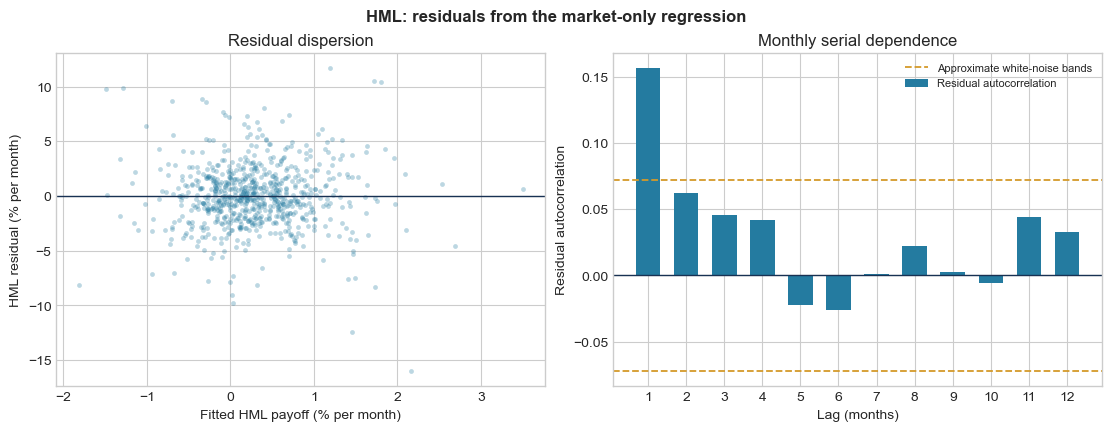

In [3]:
hml_fitted=capm.loc["HML","alpha"]+capm.loc["HML","beta_MKT"]*factor_panel["MKT"]
hml_residuals=anomaly_factors["HML"]-hml_fitted
centered=hml_residuals.to_numpy()-hml_residuals.mean()
lags=np.arange(1,13)
residual_acf=np.array([centered[lag:]@centered[:-lag]/(centered@centered) for lag in lags])
reference_band=1.96/np.sqrt(len(centered))
fig,axes=plt.subplots(1,2,figsize=(11,4.2),constrained_layout=True)
axes[0].scatter(hml_fitted*100,hml_residuals*100,s=12,alpha=.3,color="#247BA0",linewidths=0)
axes[0].axhline(0,color="#183153",linewidth=1)
axes[0].set(title="Residual dispersion",xlabel="Fitted HML payoff (% per month)",ylabel="HML residual (% per month)")
axes[1].bar(lags,residual_acf,color="#247BA0",width=.65,label="Residual autocorrelation")
axes[1].axhline(0,color="#183153",linewidth=1)
axes[1].axhline(reference_band,color="#D49A2A",linestyle="--",linewidth=1.3,label="Approximate white-noise bands")
axes[1].axhline(-reference_band,color="#D49A2A",linestyle="--",linewidth=1.3)
axes[1].set(title="Monthly serial dependence",xlabel="Lag (months)",ylabel="Residual autocorrelation",xticks=lags)
axes[1].legend(fontsize=8,loc="upper right")
fig.suptitle("HML: residuals from the market-only regression",weight="bold")
plt.show()

HML's lag-one residual autocorrelation is approximately 0.156, above the positive reference band of approximately 0.072. The remaining plotted autocorrelations lie inside the bands. This provides a concrete indication of short-run serial dependence. The residual scatter also contains substantial dispersion and extreme observations, but these features alone do not establish heteroskedasticity.

Newey–West allows both heteroskedasticity and serial dependence when estimating coefficient uncertainty. It leaves the OLS alpha, beta, residuals, and fitted returns unchanged. We retain the notebook's 12-lag convention, rather than selecting it from this plot. The diagnostics do not determine an optimal lag length, and Newey–West does not repair omitted factors or unstable exposures.

### 2.3 CAPM spanning results

The table compares conventional OLS and Newey–West alpha inference using identical coefficients and observations. Alpha and both standard errors are in percent per month. Market beta, coefficient statistics, and adjusted $R^2$ are dimensionless. The OLS statistic conventionally uses a finite-sample Student distribution under the classical normal-error assumptions, whereas the Newey–West statistic uses the asymptotic approximation explained above.

In [4]:
results=pd.DataFrame({
    "Alpha (%)":capm["alpha"]*100,
    "OLS SE (%)":capm_ols["alpha_se"]*100,
    "OLS t":capm_ols["alpha_t"],
    "NW SE (%)":capm["alpha_se"]*100,
    "NW t":capm["alpha_t"],
    "Market beta":capm["beta_MKT"],
    "NW beta t":capm["beta_MKT_t"],
    "Adjusted R²":capm["adjusted_r_squared"],
})
display(results)

,Alpha (%),OLS SE (%),OLS t,NW SE (%),NW t,Market beta,NW beta t,Adjusted R²
asset,,,,,,,,
SMB,0.084,0.108,0.772,0.124,0.673,0.188,6.572,0.075
HML,0.361,0.108,3.336,0.148,2.443,-0.135,-2.599,0.040
RMW,0.338,0.081,4.182,0.102,3.303,-0.092,-2.293,0.033
CMA,0.346,0.071,4.848,0.090,3.850,-0.165,-5.397,0.127


Newey–West standard errors exceed their conventional OLS counterparts for all four candidates in this sample. For HML, the alpha standard error increases from approximately 0.108% to 0.148% per month, reducing the statistic from 3.34 to 2.44. This makes the evidence less strong, although the nominal 5% conclusion is unchanged. Robust standard errors need not always be larger.

HML, RMW, and CMA have positive monthly CAPM alphas of approximately 0.361%, 0.338%, and 0.346%, respectively. Their absolute Newey–West $t$-statistics exceed 1.96, providing evidence against zero alpha at the nominal 5% two-sided level in each individual test. SMB's estimated alpha is approximately 0.084% per month and is not statistically distinguishable from zero. This failure to reject does not establish that SMB is spanned.

The estimated market loadings are positive for SMB and negative for HML, RMW, and CMA. Adjusted $R^2$ ranges from roughly 3% to 13%, so market exposure explains only a limited share of monthly variation. The alpha tests, rather than low fit, provide the evidence against CAPM spanning.

For an investor using MKT as the benchmark, the significant positive alphas suggest that HML, RMW, and CMA may expand the investment opportunity set. That interpretation depends on the estimated relationships persisting and the trading assumptions being feasible. The results do not establish distinct economic mechanisms, structural risk premia, or guaranteed future abnormal returns. These are individual tests, rather than the joint model test introduced in Notebook 07.

### 2.4 Visualizing the regressions

The scatterplots place each candidate's monthly payoff against the market excess return. The fitted intercept corresponds to its estimated alpha, and the slope corresponds to its market beta.

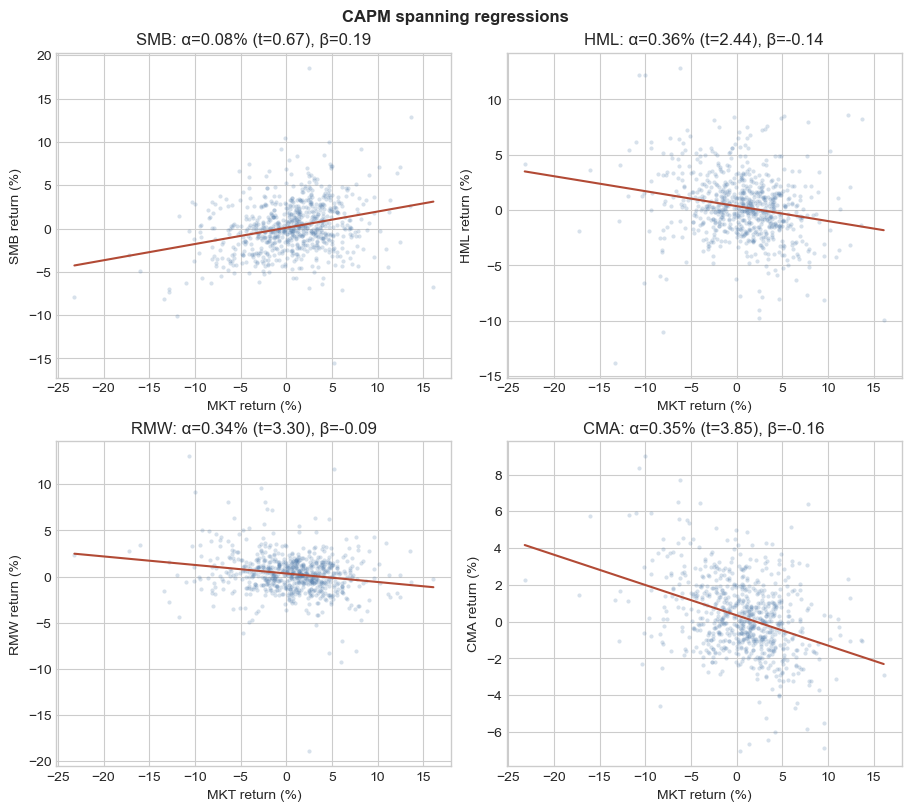

In [5]:
fig,axes=plt.subplots(2,2,figsize=(9,8),constrained_layout=True); x=factor_panel["MKT"]*100
for ax,name in zip(axes.flat,anomaly_factors):
    sample=pd.concat([x.rename("MKT"),(anomaly_factors[name]*100).rename(name)],axis=1).dropna(); grid=np.linspace(sample.MKT.min(),sample.MKT.max(),100); alpha=capm.loc[name,"alpha"]*100; beta=capm.loc[name,"beta_MKT"]
    ax.scatter(sample.MKT,sample[name],s=9,alpha=.22,color="#4C78A8",linewidths=0); ax.plot(grid,alpha+beta*grid,color="#B24A35",lw=1.5)
    ax.set(title=f"{name}: α={alpha:.2f}% (t={capm.loc[name,'alpha_t']:.2f}), β={beta:.2f}",xlabel="MKT return (%)",ylabel=f"{name} return (%)")
fig.suptitle("CAPM spanning regressions",weight="bold"); plt.show()

The fitted lines visualize the same regressions rather than provide a separate test. Their intercepts correspond to the table's estimated alphas, while their relatively shallow slopes and widely dispersed monthly observations are consistent with the low adjusted $R^2$ values. HML, RMW, and CMA therefore sit above the zero-alpha CAPM benchmark on average, whereas SMB's estimated intercept is too imprecise to distinguish from zero. The plots reinforce the statistical result, but significance is determined by the Newey–West $t$-statistics in the table—not by visual distance from the fitted line.

<a id="newey-west-covariance"></a>

## Optional technical note: Newey–West covariance

The main application requires understanding the coefficient estimate, its uncertainty, and the residual diagnostics. The following formulas specify the implementation for readers who want to reproduce the covariance calculation.

Let $\mathbf x_t=(1,\mathbf F_t')'$ contain $d=K+1$ regressors, with $X$ having rows $\mathbf x_t'$. Newey and West (1987) estimate uncertainty from the residual scores $\mathbf z_t=\mathbf x_t\widehat\varepsilon_t$. Define


$$\widehat\Gamma_\ell=\frac1T\sum_{t=\ell+1}^T\mathbf z_t\mathbf z_{t-\ell}',\qquad
\widehat S_L=\widehat\Gamma_0+\sum_{\ell=1}^L\left(1-\frac{\ell}{L+1}\right)(\widehat\Gamma_\ell+\widehat\Gamma_\ell').$$

With $Q=X'X/T$, the package's Bartlett-kernel HAC covariance, including its degrees-of-freedom correction, is

$$\widehat{\operatorname{Var}}(\widehat{\boldsymbol\theta})=\frac{T}{T-d}\frac1T Q^{-1}\widehat S_L Q^{-1}.$$


The correction $T/(T-d)$ matches the existing public API. The covariance formulas change standard errors, not the OLS coefficients.

## References

- Fama, E. F., and French, K. R. (1992). The cross-section of expected stock returns. *The Journal of Finance*, 47(2), 427–465. [DOI](https://doi.org/10.1111/j.1540-6261.1992.tb04398.x).

- Fama, E. F., and French, K. R. (1993). Common risk factors in the returns on stocks and bonds. *Journal of Financial Economics*, 33(1), 3–56. [DOI](https://doi.org/10.1016/0304-405X(93)90023-5).

- Fama, E. F., and French, K. R. (2015). A five-factor asset pricing model. *Journal of Financial Economics*, 116(1), 1–22. [DOI](https://doi.org/10.1016/j.jfineco.2014.10.010).

- French, K. R. (n.d.). Description of Fama/French five factors (2×3). *Data Library, Dartmouth College*. [Construction details](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/f-f_5_factors_2x3.html). Accessed 10 October 2026.

- Gibbons, M. R., Ross, S. A., and Shanken, J. (1989). A test of the efficiency of a given portfolio. *Econometrica*, 57(5), 1121–1152. [DOI](https://doi.org/10.2307/1913625).

- Jensen, M. C. (1968). The performance of mutual funds in the period 1945–1964. *The Journal of Finance*, 23(2), 389–416. [DOI](https://doi.org/10.1111/j.1540-6261.1968.tb00815.x).

- Lintner, J. (1965). The valuation of risk assets and the selection of risky investments in stock portfolios and capital budgets. *The Review of Economics and Statistics*, 47(1), 13–37. [DOI](https://doi.org/10.2307/1924119).

- Markowitz, H. (1952). Portfolio selection. *The Journal of Finance*, 7(1), 77–91. [DOI](https://doi.org/10.1111/j.1540-6261.1952.tb01525.x).

- Newey, W. K., and West, K. D. (1987). A simple, positive semi-definite, heteroskedasticity and autocorrelation consistent covariance matrix. *Econometrica*, 55(3), 703–708. [DOI](https://doi.org/10.2307/1913610).

- Sharpe, W. F. (1964). Capital asset prices: A theory of market equilibrium under conditions of risk. *The Journal of Finance*, 19(3), 425–442. [DOI](https://doi.org/10.1111/j.1540-6261.1964.tb02865.x).
